# Example: Analysis of a Cash Secured Put Position in AMD
In this example, we analyze a cash secured put on `AMD`: we sell a put and set aside enough cash to buy the shares at the strike price if the put is exercised. Its profit at expiration is that of the short put.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Compute the profit of a cash secured put:__ Compute the breakeven, maximum profit, and maximum loss of a short put backed by cash, and plot its profit at expiration.
> * __Estimate the probabilities of the outcomes:__ Simulate the share price at expiration with risk-neutral geometric Brownian motion, and compute the probabilities of a loss, of the maximum profit, and of exercise.
> * __Compare the probability of exercise with Delta:__ Compute the put's Delta on the binomial tree, and compare its size with the risk-neutral probability of exercise.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
To start, load the options data using [the `MyOptionsChainDataSet(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MyOptionsChainDataSet) and store the metadata in the `metadata::Dict{String,Any}` variable and the options chain data in the `optionschain::DataFrame` variable.

In [2]:
metadata, optionschain, ticker = let
    
    # initialize -
    ticker = "amd-2026"; # options chain for AMD on 2026-10-26
    options_dataset = MyOptionsChainDataSet(ticker = ticker);
    metadata = options_dataset.metadata;
    optionschain = options_dataset.data;

    (metadata, optionschain, ticker) # return
end;

What's in the `metadata::Dict{String,Any}` dictionary? 

In [3]:
let

    # initialize -
    df = DataFrame();
    fields = metadata |> keys |> collect |> sort;

    for i ∈ eachindex(fields)
        field = fields[i];
        row_df = (
            field = field |> String,
            value = metadata[field] |> string,
        );
        push!(df, row_df);
    end

    # make a table -
    pretty_table(
         df;
         fit_table_in_display_horizontally = false,
         
         table_format = TextTableFormat(borders = text_table_borders__compact)
    );

end

 ---------------------------- --------------
                       field          value 
                      String         String 
 ---------------------------- --------------
                         DTE             53
                      atm_IV         0.5617
             expiration_date     2026-12-18
       historical_volatility         0.5659
                   is_weekly          false
               purchase_date     2026-10-26
                      source   barchart.com
  underlying_share_price_ask         532.00
  underlying_share_price_bid         531.30
  underlying_share_price_mid         531.26
 ---------------------------- --------------


What about the `optionschain::DataFrame` variable?

In [4]:
optionschain

Row,Strike,Moneyness,Bid,Mid,Ask,Last,Volume,Open Int,IV,Delta,Type
,Float64,Float64,Float64,Float64,Float64,Float64,Int64,String7,Float64,Float64,String7
1,5.0,0.9906,524.2,526.53,528.85,517.3,0,"1,074",5.2163,0.9996,Call
2,10.0,0.9812,518.9,521.4,523.9,479.51,0,4,3.7202,0.9998,Call
3,15.0,0.9718,514.3,516.63,518.95,0.0,0,0,3.8539,0.9992,Call
4,20.0,0.9624,509.3,511.63,513.95,466.97,0,956,3.4532,0.9992,Call
5,25.0,0.953,504.1,506.55,509.0,427.94,0,212,2.9877,0.9994,Call
6,30.0,0.9436,499.6,501.83,504.05,457.14,0,208,3.167,0.9986,Call
7,35.0,0.9342,494.65,496.85,499.05,479.33,0,9,2.9794,0.9985,Call
8,40.0,0.9247,488.4,491.17,493.95,483.4,1,13,1.9981,0.9999,Call
9,45.0,0.9153,484.25,486.7,489.15,425.63,0,101,2.4434,0.9991,Call


### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, and permissible values. We approximate the risk-free rate $g_{y}$ with the yield on the 13-week Treasury bill on the quote date, and compute the accumulation factor $\mathcal{D}_{T,0}(g_{y})=e^{g_{y}T}$ that grows today's cash flows to expiration.

In [5]:
Sₒ = metadata["underlying_share_price_mid"] |> x-> parse(Float64, x); # mid underlying price on purchase date, 2026-10-26

Other constants:

In [6]:
Δt = (1/365); # options use 365 day year
DTE = metadata["DTE"] |> x-> parse(Float64, x); # days to expiration
τ_bill = 91/365; # term of the 13-week Treasury bill (years)
y_bill = 0.0415; # 13-week bill coupon-equivalent yield on 2026-10-26, U.S. Treasury Daily Treasury Bill Rates; update it if you change the quote date
# https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_bill_rates&field_tdr_date_value_month=202610
risk_free_rate = log(1 + y_bill*τ_bill)/τ_bill; # continuously compounded risk-free rate gᵧ (1/yr)
𝒟 = exp(risk_free_rate*DTE*Δt); # accumulation factor from today to expiration (dimensionless)
h = 8*DTE |> x-> floor(Int, x); # number of steps in the binomial tree that computes Delta (8 per day)
w = 0.3; # width parameter: we choose among puts with (1-w)*Sₒ ≤ K < Sₒ
θ = -1; # long/short indicator: -1 = short, +1 = long

___

## Task 1: Select a random put option from the dataset
In this task, we'll select put option contracts such that $\left(1-w\right)\cdot{S(0)}\leq{K}<S(0)$ where $w>0$, and we hold a long cash position equal to the strike price of the put option contract. 

Let's begin by filtering the contracts in the `optionschain::DataFrame` to include only `put` contracts that obey the strike price constraint. 
We'll use the [filter function](https://dataframes.juliadata.org/stable/lib/functions/#Base.filter) exported by the [DataFrames.jl package](https://github.com/JuliaData/DataFrames.jl) in combination with the [Julia pipe operator](https://docs.julialang.org/en/v1/manual/functions/#Function-composition-and-piping). Save the filtered selection of put contracts in the `put_contracts::DataFrame` variable:

In [7]:
put_contracts = filter(:Type=>x->x == "Put", optionschain) |> y -> filter(:Strike=> x-> (x < Sₒ && x ≥ (1-w)*Sₒ), y)

Row,Strike,Moneyness,Bid,Mid,Ask,Last,Volume,Open Int,IV,Delta,Type
,Float64,Float64,Float64,Float64,Float64,Float64,Int64,String7,Float64,Float64,String7
1,380.0,-0.2851,3.8,3.9,4.0,4.1,31,"2,297",0.6352,-0.0633,Put
2,390.0,-0.2663,4.6,4.7,4.8,4.68,13,"1,863",0.6254,-0.0751,Put
3,400.0,-0.2474,5.45,5.6,5.75,5.55,165,"9,256",0.6147,-0.0883,Put
4,410.0,-0.2286,6.55,6.7,6.85,6.65,158,"2,093",0.6057,-0.1037,Put
5,420.0,-0.2098,7.9,8.05,8.2,8.02,89,"2,712",0.5988,-0.1216,Put
6,430.0,-0.191,9.4,9.6,9.8,9.62,60,"1,511",0.5919,-0.1415,Put
7,440.0,-0.1722,11.3,11.48,11.65,11.4,104,"2,698",0.587,-0.1642,Put
8,450.0,-0.1534,13.4,13.6,13.8,13.4,275,"3,704",0.5821,-0.1888,Put
9,460.0,-0.1346,15.8,16.03,16.25,15.95,223,"4,765",0.5775,-0.2155,Put


Select a random contract from the `put_contracts::DataFrame` collection; this will be our put leg of the cash-secured put. We fix the random seed, so every run picks the same put; change `5660` to pick another. Save the data for this contract in the `put_leg_data::DataFrameRow` variable:

In [8]:
Random.seed!(5660); # fix the random choice; change the seed to pick another put
put_leg_data = nrow(put_contracts) |> i-> put_contracts[rand(1:i),:] # fancy!

Row,Strike,Moneyness,Bid,Mid,Ask,Last,Volume,Open Int,IV,Delta,Type
,Float64,Float64,Float64,Float64,Float64,Float64,Int64,String7,Float64,Float64,String7
4,410.0,-0.2286,6.55,6.7,6.85,6.65,158,"2,093",0.6057,-0.1037,Put


Next, build a [`MyAmericanPutContractModel` instance](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyAmericanPutContractModel) using the put contract data and store this contract model in the `put_contract_model::MyAmericanPutContractModel` variable. 

To access data from the `DataFrameRow`, pass in the column name. For example, to get the strike price, you would say: `put_leg_data[:Strike]`. For the premium value, use the midpoint value.

In [9]:
put_contract_model = build(MyAmericanPutContractModel, (
    K = put_leg_data[:Strike], 
    premium = put_leg_data[:Mid], # mark price
    IV = put_leg_data[:IV], # implied volatility (decimal)
    DTE = (DTE)*Δt,
    sense = θ, # short put θ = -1
    copy = 1,
)); 

___

## Task 2: Compute the Breakeven, Maximum Profit, and Maximum Loss
In this task, let's begin by computing the breakeven of the put contract we constructed above. The payoff per share at expiration for a put option contract is given by:
$$
\begin{align*}
V_{p}(K,S(T)) = \max\left(K - S(T),~0\right)
\end{align*}
$$
where $K$ denotes the strike price and $S(T)$ is the share price at expiration. The `seller` charges the `buyer` a premium $\mathcal{P}_{p}$ for each contract. Because we sold this contract, we are in a short position. For the general case, the profit for a put contract is given by:
$$
\begin{equation*}
\hat{P}(S(T)) = \theta\cdot\left({V_{p}}(K,S(T)) - \mathcal{D}_{T,0}(g_{y})\cdot\mathcal{P}_{p}\right)
\end{equation*}
$$
where $\theta$ is a direction parameter; $\theta = 1$ if we are `long` the contract, while $\theta = -1$ if we are `short` the contract, and $\mathcal{D}_{T,0}(g_{y})=e^{g_{y}T}$ grows the premium to expiration. The breakeven at expiration for both a long or short put contract is the share price $S^{\ddagger}$ at expiration such that $\hat{P}(S^{\ddagger}) = 0$. Thus, for our short `AMD` put, the breakeven share price $S^{\ddagger}$ (USD/share) would be:
$$
\begin{equation*}
S^{\ddagger} = K - \mathcal{D}_{T,0}(g_{y})\cdot\mathcal{P}_{p}
\end{equation*}
$$
For the buyer to make money, the share price must fall below the breakeven price $S^{\ddagger}$. For the seller to make money, the share price must remain above the breakeven price. 

Compute the break-even price for the put contract and store this in the `computed_breakeven_price::Float64` variable:

In [10]:
computed_breakeven_price = put_contract_model.K - 𝒟*put_contract_model.premium; # premium grown to expiration

Let's show the breakeven with the maximum profit and the maximum loss:

In [11]:
let

    # initialize -
    K = put_contract_model.K; # strike price (USD/share)
    max_profit = 𝒟*put_contract_model.premium; # premium grown to expiration, when the put is not exercised (USD/share)
    max_loss = K - 𝒟*put_contract_model.premium; # if the share price falls to zero, a positive number (USD/share)

    # show the maximum profit, the breakeven, and the maximum loss -
    df = DataFrame(quantity = ["maximum profit, S(T) ≥ K", "breakeven S‡", "maximum loss, S(T) = 0"],
        value = [max_profit, computed_breakeven_price, max_loss], units = ["USD/share", "USD/share", "USD/share"]);
    pretty_table(df; column_labels = ["quantity", "value", "units"], alignment = [:l, :r, :l],
        formatters = [fmt__printf("%.2f", [2])], fit_table_in_display_horizontally = false,
        table_format = TextTableFormat(borders = text_table_borders__compact));
end

 -------------------------- -------- -----------
  quantity                    value   units     
 -------------------------- -------- -----------
  maximum profit, S(T) ≥ K     6.74   USD/share
  breakeven S‡               403.26   USD/share
  maximum loss, S(T) = 0     403.26   USD/share
 -------------------------- -------- -----------


### Visualize
Now that we have analytically computed the breakeven value, let's visualize the profit diagram at expiration for the cash secured put. To do this, build an array of share prices at expiration and save this in the `share_price_array::Array{Float64,1}` variable. 

We'll look at a range from $w\cdot S^{\ddagger}$ to $\left(2-w\right) \cdot S(0)$, where $w$ is a width parameter $0<w<1$ that we specify.

In [12]:
share_price_array = let

    w = 0.95; # width of range to explore. Adjust me to see what happens
    number_of_steps = 1001; # leave me alone!
    K = put_contract_model.K; # strike price
    Bₚ = computed_breakeven_price; # breakeven price 

    # build a range, then pass that to collect (which gives an array)
    share_price_array = range((w)*Bₚ, stop = (2-w)*Sₒ, length = number_of_steps) |> collect;

    # return the data
    share_price_array;
end;

Finally, compute the profit for the short put. We compute the profit by [calling the `profit(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.profit) and save the profit values in the `profit_array` variable. The [`profit(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.profit) takes two arguments, the contract models as an array and the share price array, and the accumulation factor `𝒟` as a keyword argument.

The `profit_array` will be a `1001`$\times$ `3` array, in which each row is a possible value for the share price at expiration $S(T)$. Column `1` holds the possible $S(T)$ values, column `2` holds the profit for the short put, column `3` holds the overall profit for the composite trade.

In [13]:
profit_array = profit([put_contract_model], share_price_array; 𝒟 = 𝒟) # premium grown to expiration

1001×3 Matrix{Float64}:
 383.097  -20.163    -20.163
 383.271  -19.9883   -19.9883
 383.446  -19.8135   -19.8135
 383.621  -19.6388   -19.6388
 383.796  -19.4641   -19.4641
 383.97   -19.2894   -19.2894
 384.145  -19.1146   -19.1146
 384.32   -18.9399   -18.9399
 384.495  -18.7652   -18.7652
 384.669  -18.5904   -18.5904
 384.844  -18.4157   -18.4157
 385.019  -18.241    -18.241
 385.193  -18.0663   -18.0663
   ⋮                 
 555.901    6.74029    6.74029
 556.076    6.74029    6.74029
 556.25     6.74029    6.74029
 556.425    6.74029    6.74029
 556.6      6.74029    6.74029
 556.775    6.74029    6.74029
 556.949    6.74029    6.74029
 557.124    6.74029    6.74029
 557.299    6.74029    6.74029
 557.474    6.74029    6.74029
 557.648    6.74029    6.74029
 557.823    6.74029    6.74029

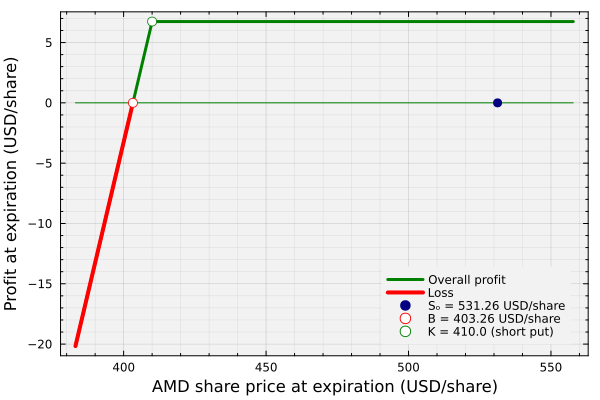

In [14]:
let
    # initialize 
    N = length(profit_array[:,1]); # how many steps do we have?
    BEL = zeros(N);
    K = put_contract_model.K;

    # SPL_vertical = range(-100,stop=100,length=N) |> collect;
    SPL_horizontal = Sₒ*ones(N);
    STRIKE_horizontal = K;
    max_profit = 𝒟*(put_contract_model.premium);
    B = computed_breakeven_price;

    # setup the coloring -
    profit_idx = findall(>(0), profit_array[:,end])
    # alternative_loss_index = findall(x->x ≥ max_profit_intersection, profit_array[:,end]);
    loss_array = profit_array[:,:]; loss_array[profit_idx,:] .= NaN
    
    plot(profit_array[:,1],profit_array[:,end], lw=3, c=:green, label="Overall profit", 
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent, legendfontsize=8, legend=:bottomright,
        xminorticks=5, yminorticks=5, minorgrid=true);
    plot!(profit_array[:,1], BEL, c=:green, lw=1, label="")
    plot!(loss_array[:,1], loss_array[:,3], lw=4, label="Loss", c=:red)
    scatter!([Sₒ], [0], ms=5, c=:navy, msc=:navy, ls=:dash, label="Sₒ = $(Sₒ) USD/share")
    scatter!([B], [0], ms=5, c=:white, msc=:red, ls=:dash, label="B = $(round(B, digits=2)) USD/share")
    scatter!([K],[max_profit], ms=5, label = "K = $(K) (short put)", msc=:green, c=:white)
    
    xlabel!("AMD share price at expiration (USD/share)", fontsize=18)
    ylabel!("Profit at expiration (USD/share)", fontsize=18)
end

___

## Task 3: Probability of Outcomes
In this task, we estimate the probability of certain outcomes for the cash-secured put position at expiration. We'll consider three scenarios:

> __Scenarios:__
>
> * __Scenario 1: Loss__. In this scenario, the share price at expiration $S(T)$ is below the breakeven $S^{\ddagger}$ (stored as `B` in the code). The probability of this scenario is $\mathbb{P}(S(T)<S^{\ddagger}) = F_{S}\left(S^{\ddagger}\right)$.
> * __Scenario 2: Maximum profit__. In this scenario, the share price at expiration is at or above the strike price, $S(T)\geq K$, so the put expires worthless and we keep the premium. The probability of this scenario is $\mathbb{P}(S(T)\geq K) = \mathbb{P}(S(T)>K) = 1 - F_{S}\left(K\right)$.
> * __Scenario 3: Exercise__. In this scenario, the put finishes more than one cent in the money, $S(T)<K-\epsilon$ with $\epsilon=$ `0.01` USD/share, and we buy the shares at the strike price. The probability of this scenario, the probability of exercise (POE) at expiration, is $\mathbb{P}(S(T)<K-\epsilon) = F_{S}\left(K-\epsilon\right)$.

To start, let's build a model of the future underlying share price at expiration $S(T)$. Build an instance of the [MyGeometricBrownianMotionEquityModel type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.MyGeometricBrownianMotionEquityModel) which holds values for the drift `μ` and volatility `σ` parameters using a [custom build(...) method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.build-Tuple{Type{MyGeometricBrownianMotionEquityModel},%20NamedTuple}).

> __Risk-neutral pricing__: We set the drift parameter to the risk-free rate $\mu = g_{y}$ (because options use a risk-neutral probability measure), and the volatility to the put's implied volatility $\sigma = \text{IV}$ from the options chain data. This gives us the risk-neutral simulation of the underlying share price at expiration, with the same drift and volatility we use for the put's Delta at the end of this task. The probabilities we compute are risk-neutral probabilities, not our forecast of the share price.

We'll save the model in the `model::MyGeometricBrownianMotionEquityModel` variable, and the implied volatility value in the `σ̄::Float64` variable.

In [15]:
model, σ̄ = let

    # Step 1: get the implied volatility 
    σ̄ = put_leg_data[:IV];

    # Step 2: build the GBM model
    model = build(MyGeometricBrownianMotionEquityModel, (
        μ = risk_free_rate,
        σ = σ̄
    ));

    model, σ̄
end;

Now that we have a populated [MyGeometricBrownianMotionEquityModel instance](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.MyGeometricBrownianMotionEquityModel) holding the `AMD` data, let's generate `number_of_samples` possible future share price values using the [sample(...) function exported by the VLQuantitativeFinancePackage.jl package](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyMultipleAssetGeometricBrownianMotionEquityModel,%20NamedTuple}).
* The [sample method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyMultipleAssetGeometricBrownianMotionEquityModel,%20NamedTuple}) takes a `model::MyGeometricBrownianMotionEquityModel` instance as the first argument, along with the time values that we wish to sample: `T₁::Float64` is the start time, `T₂::Float64` is the stop time (in units of `years`), `Δt::Float64` is the time step (in units of `years`), and `Sₒ::Float64` denotes the initial share price (in units of `USD/share`). Finally, we pass in the number of samples we want to generate in the `number_of_paths` argument.
* The [sample method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyMultipleAssetGeometricBrownianMotionEquityModel,%20NamedTuple}) generates `number_of_paths` sample paths from $T_{1}\rightarrow{T}_{2}$ in steps of $\Delta{t}$. However, we only want the share prices corresponding to the duration of the contract, i.e., $T_{2} = \text{DTE}$. Thus, we pass the full `samples` array [using the Julia pipe operator](https://docs.julialang.org/en/v1/manual/functions/#Function-composition-and-piping) to a slicing operation where we select columns `2:end` of the last row (col 1 holds the time). We store the `number_of_paths` samples of the share price at $T_{2}$ in the `endpoint::Array{Float64,1}` variable.

So what do we get?

In [16]:
endpoint = let
    number_of_samples = 25000; # TODO: adjust me!
    endpoint = VLQuantitativeFinancePackage.sample(model, (
        T₁ = 0.0,
        T₂ = (DTE)*(Δt),
        Δt = Δt,
        Sₒ = Sₒ
    ), number_of_paths = number_of_samples) |> samples -> samples[end,2:end]; # get last row from col 2 -> number_of_paths

    endpoint;
end;

We've previously shown that sampling a GBM model emits a LogNormal share price distribution. Fit a [LogNormal distribution exported by the Distributions.jl package](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.LogNormal) to the samples using the [fit_mle(...) function exported by Distributions.jl](https://juliastats.org/Distributions.jl/stable/fit/#Distributions.fit_mle-Tuple{Any,%20Any}), and save this in the `d_gbm::LogNormal` variable.

In [17]:
d_gbm = fit_mle(LogNormal, endpoint); # risk-neutral ℚ: the log-normal distribution of the simulated GBM share prices

### Cumulative distribution
Next, estimate [the cumulative distribution function (CDF)](https://en.wikipedia.org/wiki/Cumulative_distribution_function) for the share price distribution. 
We can query the cumulative distribution function $F_{S}(\star)$ for the risk-neutral GBM distribution `d_gbm` using [the `cdf(...)` function exported by the Distributions.jl package](https://github.com/JuliaStats/Distributions.jl?tab=readme-ov-file).

In [Julia we can use the `cdf(...)` function exported from the Distributions.jl package](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.cdf-Tuple{UnivariateDistribution,%20Real}) to compute $F_{S}\left(x\right)$.

#### Visualize
`Unhide` the code block below to see how we plotted the cumulative distribution function (CDF) for `AMD` share price at contract expiration using the risk-neutral geometric Brownian motion `d_gbm` model:

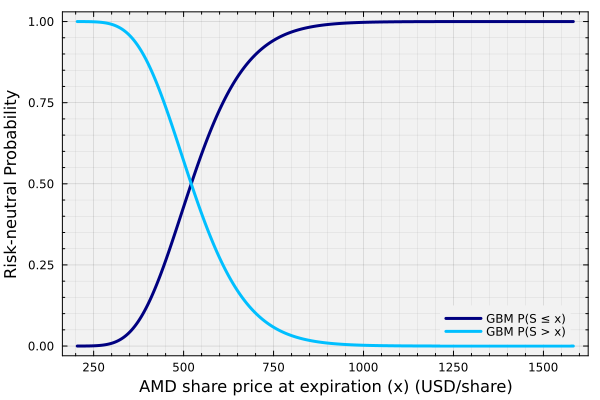

In [18]:
let
    number_of_samples = length(endpoint);
    X = Array{Float64,2}(undef, number_of_samples, 2);
    S = Array{Float64,1}();
    for i ∈ eachindex(endpoint)
        push!(S,endpoint[i]);
    end
    S = sort(S);
    
    for i ∈ eachindex(S)
    
        X[i,1] = S[i];
        X[i,2] = cdf(d_gbm, S[i]);
    end

    plot(X[:,1], X[:,2], lw=3, c=:navy, label="GBM P(S ≤ x)", xminorticks=5, yminorticks=5, minorgrid=true,
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent, legendfontsize=8, legend=:bottomright)
    plot!(X[:,1], 1 .- X[:,2], lw=3, c=:deepskyblue1, label="GBM P(S > x)")

    xlabel!("AMD share price at expiration (x) (USD/share)", fontsize=18);
    ylabel!("Risk-neutral Probability", fontsize=18);
end

Now that we have the cumulative distribution function for the share price distribution, let's compute the probability of observing each of the three scenarios outlined above.

> __Scenario 1: Loss__. In this scenario, the share price at expiration $S(T)$ is below the breakeven $S^{\ddagger}$. The probability of this scenario is $\mathbb{P}(S(T)<S^{\ddagger}) = F_{S}\left(S^{\ddagger}\right)$.

Let's save the probability of this scenario occurring in the `p_downside_loss_gbm::Float64` variable.

In [19]:
p_downside_loss_gbm = let

    # initialize
    B = computed_breakeven_price; # breakeven (USD/share)

    # compute P(S(T) < B) for the GBM model
    p_downside_loss_gbm = cdf(d_gbm, B);

    # return data -
    p_downside_loss_gbm
end;

In [20]:
println("Scenario 1: Probability of loss = $(p_downside_loss_gbm)")

Scenario 1: Probability of loss = 0.13407402666595927


We've seen how to compute the probability of a loss using the cumulative distribution function for the share price distribution. Next, let's compute the probability of maximum profit.

> __Scenario 2: Maximum profit__. In this scenario, the share price at expiration is at or above the strike price, $S(T)\geq K$, and the put expires worthless. The probability of this scenario is $\mathbb{P}(S(T)\geq K) = \mathbb{P}(S(T)>K) = 1 - F_{S}\left(K\right)$.

We'll save the probability of this scenario occurring in the `p_max_profit_gbm::Float64` variable.

In [21]:
p_max_profit_gbm = let

    # initialize
    K = put_contract_model.K; # strike price (USD/share)

    # compute the probability P(S(T) ≥ K) for the GBM: the put expires worthless
    p_max_profit_gbm = 1 - cdf(d_gbm, K);

    # return data -
    p_max_profit_gbm
end;

In [22]:
println("Scenario 2: Probability of max profit = $(p_max_profit_gbm)")

Scenario 2: Probability of max profit = 0.8498513701676238


Next, let's compute the probability of exercise. If we are short the put contract, the put is exercised at expiration when it finishes more than one cent in the money, and we buy the shares at the strike price.

> __Scenario 3: Exercise__. In this scenario, $S(T)<K-\epsilon$ with $\epsilon=$ `0.01` USD/share. The probability of this scenario, the probability of exercise (POE) at expiration, is $\mathbb{P}(S(T)<K-\epsilon) = F_{S}\left(K-\epsilon\right)$.

We'll save the probability of this scenario occurring in the `p_exercise_gbm::Float64` variable.

In [23]:
p_exercise_gbm = let
    
    ϵ = 0.01; # 1/100 USD
    p_exercise_gbm = nothing;
    K = put_contract_model.K

    # compute P(S ≤ K - ϵ) for the GBM model
    p_exercise_gbm = cdf(d_gbm,K-ϵ);

    # return data -
    p_exercise_gbm
end;

In [24]:
println("Scenario 3: Probability of exercise = $(p_exercise_gbm)")

Scenario 3: Probability of exercise = 0.15012407120205132


### Probability of exercise and Delta
How close is the probability of exercise to the size of the put's Delta, $|\Delta_{p}|$? We compute Delta on the binomial tree with the same drift $g_{y}$ and volatility, the put's implied volatility, as `d_gbm`, and save it in the `delta_long_put::Float64` variable. The `delta(...)` function estimates Delta from the change in the tree premium for a `+1 USD/share` move in the share price, so its value is accurate to about `0.01`:

In [25]:
delta_long_put = let

    # initialize
    greek_value = 0.0; # initially set the greek value to 0
    contract_model = deepcopy(put_contract_model); # alias the contract model
    contract_model.sense = 1; # long put (we always compute greeks for long contracts)

    # call the greek function
    greek_value = delta(contract_model, h = h,  T = contract_model.DTE, 
        σ = contract_model.IV, Sₒ = Sₒ, μ = risk_free_rate);

    # return -
    greek_value;
end

-0.10500000000000043

Let's put the size of Delta next to the three probabilities:

In [26]:
let

    # show the risk-neutral probabilities of the three scenarios, and the size of the put's Delta -
    df = DataFrame(quantity = ["P(loss), S(T) < S‡", "P(maximum profit), S(T) ≥ K", "POE at expiration, S(T) < K - 0.01", "size of the put's Delta, |Δp|"],
        value = [p_downside_loss_gbm, p_max_profit_gbm, p_exercise_gbm, abs(delta_long_put)]);
    pretty_table(df; column_labels = ["quantity", "value"], alignment = [:l, :r],
        formatters = [fmt__printf("%.4f", [2])], fit_table_in_display_horizontally = false,
        table_format = TextTableFormat(borders = text_table_borders__compact));
end

 ------------------------------------ --------
  quantity                              value 
 ------------------------------------ --------
  P(loss), S(T) < S‡                   0.1341
  P(maximum profit), S(T) ≥ K          0.8499
  POE at expiration, S(T) < K - 0.01   0.1501
  size of the put's Delta, |Δp|        0.1050
 ------------------------------------ --------


> __What do we see?__ The size of the put's Delta is smaller than the risk-neutral probability of exercise, so it is only a rough estimate of it. For a European put on the binomial tree, $|\Delta_{p}|$ is a probability of exercise computed with a slightly larger up probability, which moves probability away from the low share prices where the put is exercised. Our put is American, so this reasoning is a guide, not a guarantee.
___

## Summary
In this example, we sold a put on `AMD`, computed its breakeven, maximum profit, and maximum loss, and estimated the risk-neutral probabilities of a loss, of the maximum profit, and of exercise, which we compared with the put's Delta.

> __Key Takeaways:__
>
> * __The premium sets the breakeven below the strike price:__ We computed the breakeven as the strike price minus the premium grown to expiration. The position earns its maximum profit, the premium grown to expiration, when the put is not exercised, and loses money only when the share price at expiration falls below the breakeven.
> * __The cumulative distribution gives the probabilities of the outcomes:__ We simulated the share price at expiration with risk-neutral geometric Brownian motion and read its cumulative distribution at the breakeven and near the strike price. This gave the risk-neutral probabilities of a loss, of the maximum profit, and of exercise.
> * __Delta is a rough estimate of the probability of exercise:__ We computed the put's Delta on the binomial tree with the same drift and volatility and compared its size with the risk-neutral probability of exercise. The size of Delta was smaller, as the tree argument for a European put suggests: its Delta is a probability of exercise computed with a larger up probability.

Understanding cash secured put positions enables traders to generate income while potentially acquiring shares at a lower price.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___